In [1]:
# ============================================================
# 06 · Cell 1 — Setup and load saved results
# ============================================================
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

SRC_DIR = Path.cwd() / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from commodity_factors.analytics import PerformanceReport, newey_west_tstat
from commodity_factors.config import PATHS

pd.set_option("display.width", 160)

PRIMARY_FACTORS = ["mom_12_1", "carry", "value", "skewness", "hedging_pressure", "tsmom_12"]
TABLES_DIR = PATHS.root / "reports" / "tables"
SLIDES_DIR = PATHS.root / "reports" / "linkedin"
SLIDES_DIR.mkdir(parents=True, exist_ok=True)


def load(name: str) -> pd.DataFrame:
    return pd.read_parquet(PATHS.processed / f"{name}.parquet")


def table(name: str) -> pd.DataFrame:
    return pd.read_csv(TABLES_DIR / f"{name}.csv", index_col=0)


# Return series
factor_returns = load("factor_returns_headline")[PRIMARY_FACTORS]
combos = load("combination_returns")
benchmarks = load("benchmarks_monthly").loc[: factor_returns.index.max()]
long_only_combo = load("long_only_multifactor_excess")["long_only_multifactor_excess"]

# Result tables
final_summary = table("05_final_summary")
event_study = table("04_event_study")
regime_table = pd.read_csv(TABLES_DIR / "04_regimes.csv", index_col=[0, 1])
aqr_validation = table("05_aqr_validation")
cost_table = table("04_cost_sensitivity")

print(f"Factor returns    : {factor_returns.index.min():%Y-%m} -> {factor_returns.index.max():%Y-%m}")
print(f"Combination       : {combos.index.min():%Y-%m} -> {combos.index.max():%Y-%m}")
print(f"Long-only tilt    : {long_only_combo.index.min():%Y-%m} -> {long_only_combo.index.max():%Y-%m}")
print(f"Tables loaded     : final_summary {final_summary.shape}, event_study {event_study.shape}, "
      f"regimes {regime_table.shape}, aqr {aqr_validation.shape}")
print(f"Slides folder     : {SLIDES_DIR}\n")

print("Headline numbers for the slides")
print(final_summary[["sharpe_net", "t_stat_nw", "max_dd_%", "evidence"]].to_string())

Factor returns    : 2002-02 -> 2026-09
Combination       : 2004-02 -> 2026-09
Long-only tilt    : 2002-02 -> 2026-09
Tables loaded     : final_summary (7, 10), event_study (7, 7), regimes (42, 6), aqr (3, 5)
Slides folder     : C:\Users\navon\OneDrive\Desktop\Cmmodities Factor Modeling\reports\linkedin

Headline numbers for the slides
                  sharpe_net  t_stat_nw   max_dd_%                                   evidence
mom_12_1            0.112627   0.621346 -65.656146                              weak (t<1.96)
carry               0.169523   0.971723 -66.006759                              weak (t<1.96)
value               0.444260   2.117579 -39.992457  moderate (t>1.96, fails multiple-testing)
skewness            0.458831   2.125274 -47.124192  moderate (t>1.96, fails multiple-testing)
hedging_pressure    0.337135   1.437783 -51.033486                              weak (t<1.96)
tsmom_12            0.398061   2.028381 -38.534359  moderate (t>1.96, fails multiple-testing)
combo

In [2]:
%%writefile src/commodity_factors/viz.py
"""Institutional-style slide template for LinkedIn carousel charts (1080 x 1350 px)."""

from __future__ import annotations

import textwrap
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.figure import Figure
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter


@dataclass(frozen=True)
class SlideStyle:
    """Palette, typography and geometry shared by every slide."""

    width_px: int = 1080
    height_px: int = 1350
    dpi: int = 150
    font_family: tuple[str, ...] = ("Arial", "Helvetica", "DejaVu Sans")
    navy: str = "#0B1F3A"
    text: str = "#1F2937"
    muted: str = "#6B7280"
    grid: str = "#E5E7EB"
    accent: str = "#B08D57"
    positive: str = "#1F6F4A"
    negative: str = "#A3292F"
    factor_colors: dict[str, str] = field(
        default_factory=lambda: {
            "mom_12_1": "#8FA9C8",
            "carry": "#C9A66B",
            "value": "#2E5E8C",
            "skewness": "#6C8E5E",
            "hedging_pressure": "#8C5A7A",
            "tsmom_12": "#4F7C82",
            "combo_equal_risk": "#0B1F3A",
            "EW_benchmark": "#9CA3AF",
        }
    )
    labels: dict[str, str] = field(
        default_factory=lambda: {
            "mom_12_1": "Momentum",
            "carry": "Carry",
            "value": "Value",
            "skewness": "Skewness",
            "hedging_pressure": "Hedging pressure",
            "tsmom_12": "Time-series momentum",
            "combo_equal_risk": "Multi-factor (equal-risk)",
            "EW_benchmark": "Commodity market (equal-weight)",
        }
    )

    @property
    def figsize(self) -> tuple[float, float]:
        return self.width_px / self.dpi, self.height_px / self.dpi

    def color(self, key: str) -> str:
        return self.factor_colors.get(key, self.muted)

    def label(self, key: str) -> str:
        return self.labels.get(key, key)

    def apply(self) -> None:
        """Set matplotlib defaults for this style."""
        mpl.rcParams.update(
            {
                "font.family": "sans-serif",
                "font.sans-serif": list(self.font_family),
                "axes.edgecolor": self.muted,
                "axes.labelcolor": self.text,
                "xtick.color": self.muted,
                "ytick.color": self.muted,
                "axes.titlesize": 9,
                "axes.labelsize": 8,
                "xtick.labelsize": 7.5,
                "ytick.labelsize": 7.5,
                "legend.fontsize": 7.5,
                "legend.frameon": False,
                "savefig.facecolor": "white",
            }
        )


def style_axes(ax: Axes, style: SlideStyle, grid_axis: str = "y") -> Axes:
    """Clean institutional axes: no top/right spines, light gridlines on one axis."""
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(style.grid)
    ax.tick_params(length=0, pad=4)
    ax.grid(False)
    if grid_axis:
        ax.grid(axis=grid_axis, color=style.grid, lw=0.7)
    ax.set_axisbelow(True)
    return ax


def percent_axis(ax: Axes, axis: str = "y", decimals: int = 0) -> None:
    """Format an axis whose values are already in percent units."""
    formatter = FuncFormatter(lambda v, _: f"{v:.{decimals}f}%")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(formatter)


class Slide:
    """One portrait slide: header (accent rule, title, subtitle), content area, footer."""

    CONTENT = {"left": 0.10, "right": 0.95, "top": 0.82, "bottom": 0.12}

    def __init__(
        self,
        title: str,
        subtitle: str,
        style: SlideStyle,
        footer: str,
        author: str,
        page: tuple[int, int] | None = None,
    ) -> None:
        self.style = style
        self.fig: Figure = plt.figure(figsize=style.figsize, dpi=style.dpi, facecolor="white")
        self._header(title, subtitle)
        self._footer(footer, author, page)

    def _header(self, title: str, subtitle: str) -> None:
        s = self.style
        self.fig.add_artist(
            Line2D([0.06, 0.16], [0.962, 0.962], color=s.accent, lw=3, transform=self.fig.transFigure)
        )
        self.fig.text(0.06, 0.945, title, fontsize=15, fontweight="bold", color=s.navy, va="top")
        self.fig.text(
            0.06, 0.900, textwrap.fill(subtitle, 78), fontsize=8.6, color=s.text, va="top",
            linespacing=1.4,
        )

    def _footer(self, footer: str, author: str, page: tuple[int, int] | None) -> None:
        s = self.style
        self.fig.add_artist(
            Line2D([0.06, 0.94], [0.062, 0.062], color=s.grid, lw=0.8, transform=self.fig.transFigure)
        )
        self.fig.text(
            0.06, 0.050, textwrap.fill(footer, 120), fontsize=5.6, color=s.muted, va="top",
            linespacing=1.4,
        )
        right = author if page is None else f"{author}   |   {page[0]} / {page[1]}"
        self.fig.text(
            0.94, 0.020, right, fontsize=6.2, color=s.navy, ha="right", va="bottom", fontweight="bold"
        )

    def axes(
        self, rect: tuple[float, float, float, float] | None = None, grid_axis: str = "y"
    ) -> Axes:
        """Single axes; rect = (left, bottom, width, height) in figure fractions."""
        c = self.CONTENT
        rect = rect or (c["left"], c["bottom"], c["right"] - c["left"], c["top"] - c["bottom"])
        return style_axes(self.fig.add_axes(rect), self.style, grid_axis)

    def grid(self, nrows: int, ncols: int = 1, grid_axis: str = "y", **gridspec_kw) -> list[Axes]:
        """Axes laid out on a grid inside the content area."""
        spec = self.fig.add_gridspec(nrows, ncols, **self.CONTENT, **gridspec_kw)
        return [style_axes(self.fig.add_subplot(cell), self.style, grid_axis) for cell in spec]

    def save(self, folder: Path, name: str) -> Path:
        folder.mkdir(parents=True, exist_ok=True)
        path = folder / f"{name}.png"
        self.fig.savefig(path, dpi=self.style.dpi, facecolor="white")
        return path


def build_carousel(figures: list[Figure], path: Path) -> Path:
    """Combine slides into one PDF (LinkedIn document post), one slide per page."""
    with PdfPages(path) as pdf:
        for figure in figures:
            pdf.savefig(figure, facecolor="white")
    return path

Writing src/commodity_factors/viz.py


Saved 02_headline_result.png


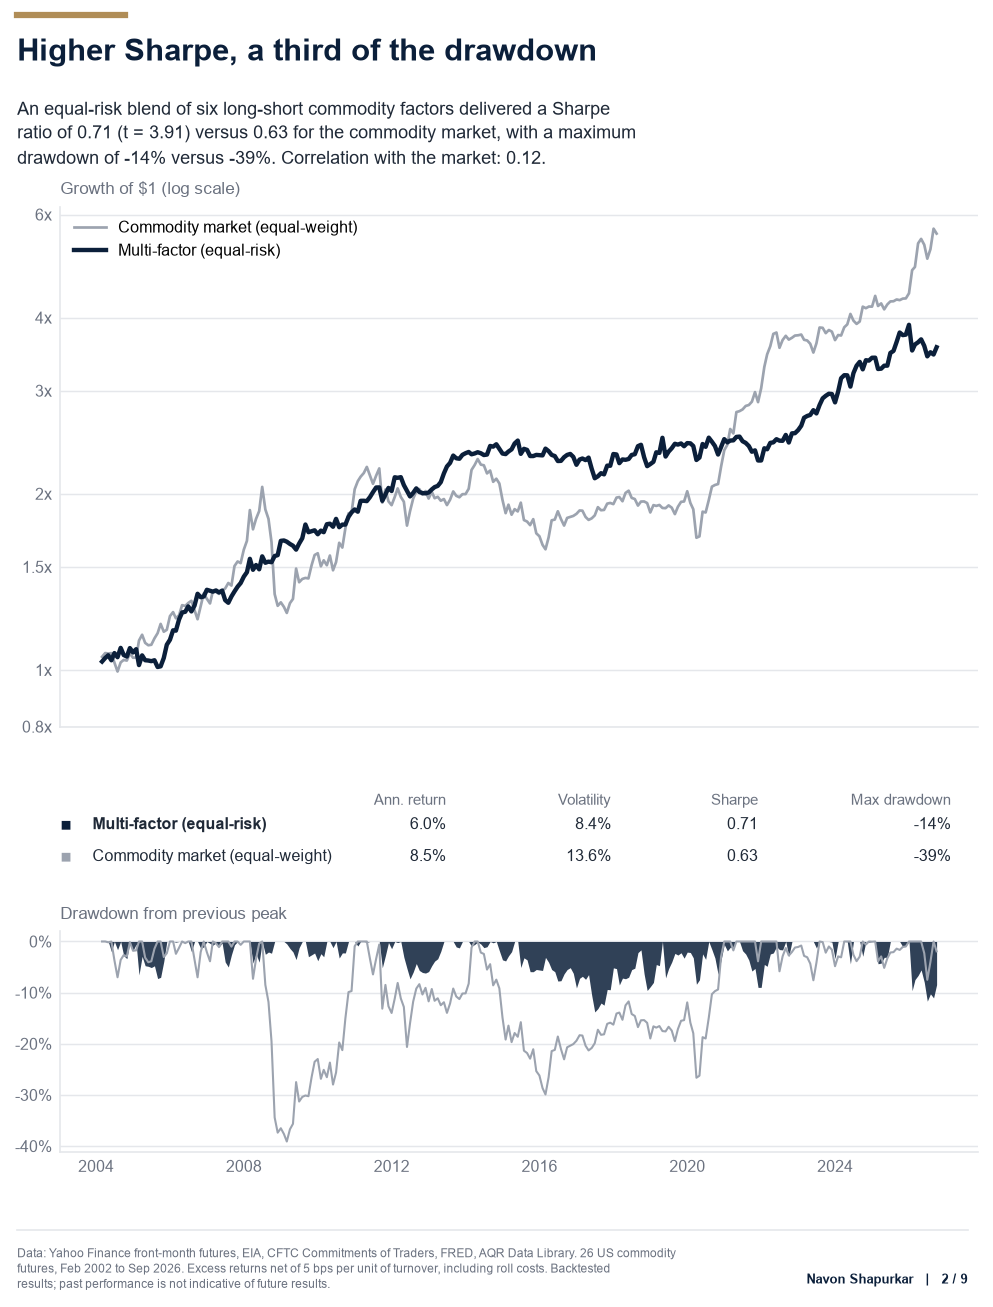

In [5]:
# ============================================================
# 06 · Cell 3 — Shared slide settings and slide 2 (headline result)
# ============================================================
from matplotlib.ticker import FuncFormatter, NullLocator

from commodity_factors.viz import Slide, SlideStyle, build_carousel, percent_axis

STYLE = SlideStyle()
STYLE.apply()
AUTHOR = "Navon Shapurkar"
TOTAL_SLIDES = 9
FOOTER = (
    "Data: Yahoo Finance front-month futures, EIA, CFTC Commitments of Traders, FRED, AQR Data Library. "
    "26 US commodity futures, Feb 2002 to Sep 2026. Excess returns net of 5 bps per unit of turnover, "
    "including roll costs. Backtested results; past performance is not indicative of future results."
)
slides: dict[int, plt.Figure] = {}


def new_slide(page: int, title: str, subtitle: str, footer: str = FOOTER) -> Slide:
    return Slide(title, subtitle, STYLE, footer, AUTHOR, (page, TOTAL_SLIDES))


def slide_stats(r: pd.Series) -> dict:
    wealth = (1 + r).cumprod()
    vol = r.std() * np.sqrt(12)
    return {
        "Ann. return": f"{r.mean() * 1200:.1f}%",
        "Volatility": f"{vol * 100:.1f}%",
        "Sharpe": f"{r.mean() * 12 / vol:.2f}",
        "Max drawdown": f"{(wealth / wealth.cummax() - 1).min() * 100:.0f}%",
    }


# Data: combination vs equal-weight commodity market, common sample
series = pd.DataFrame(
    {"combo_equal_risk": combos["combo_equal_risk"], "EW_benchmark": benchmarks["EW_all"]}
).dropna()
wealth = (1 + series).cumprod()
drawdown = (wealth / wealth.cummax() - 1) * 100
combo_t = newey_west_tstat(series["combo_equal_risk"])
sharpe = series.mean() / series.std() * np.sqrt(12)
max_dd = drawdown.min()
market_corr = series.corr().iloc[0, 1]

slide = new_slide(
    2,
        "Higher Sharpe, a third of the drawdown",
    f"An equal-risk blend of six long-short commodity factors delivered a Sharpe ratio of "
    f"{sharpe['combo_equal_risk']:.2f} (t = {combo_t:.2f}) versus {sharpe['EW_benchmark']:.2f} for the "
    f"commodity market, with a maximum drawdown of {max_dd['combo_equal_risk']:.0f}% versus "
    f"{max_dd['EW_benchmark']:.0f}%. Correlation with the market: {market_corr:.2f}.",
)
ax_top, ax_table, ax_dd = slide.grid(3, 1, height_ratios=[2.6, 0.42, 1.1], hspace=0.22)

# Panel 1: growth of $1
for key, lw in [("EW_benchmark", 1.3), ("combo_equal_risk", 2.1)]:
    ax_top.plot(wealth[key], color=STYLE.color(key), lw=lw, label=STYLE.label(key))
ax_top.set_yscale("log")
ax_top.yaxis.set_minor_locator(NullLocator())
top = wealth.max().max()
ax_top.set_yticks([t for t in [0.8, 1, 1.5, 2, 3, 4, 6, 8, 12] if t <= top * 1.1])
ax_top.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}x"))
ax_top.set_title("Growth of $1 (log scale)", loc="left", color=STYLE.muted, fontsize=8)
ax_top.legend(loc="upper left")
ax_top.tick_params(labelbottom=False)

# Panel 2: statistics strip
ax_table.axis("off")
columns, xs = ["Ann. return", "Volatility", "Sharpe", "Max drawdown"], [0.42, 0.60, 0.76, 0.97]
for x, column in zip(xs, columns):
    ax_table.text(x, 0.92, column, ha="right", va="top", fontsize=7.2, color=STYLE.muted,
                  transform=ax_table.transAxes)
for row, key in enumerate(["combo_equal_risk", "EW_benchmark"]):
    y, values = 0.55 - row * 0.38, slide_stats(series[key])
    ax_table.text(0.0, y, "■", color=STYLE.color(key), fontsize=9, va="center", transform=ax_table.transAxes)
    ax_table.text(0.035, y, STYLE.label(key), fontsize=7.6, va="center", color=STYLE.text,
                  fontweight="bold" if row == 0 else "normal", transform=ax_table.transAxes)
    for x, column in zip(xs, columns):
        ax_table.text(x, y, values[column], ha="right", va="center", fontsize=7.8, color=STYLE.text,
                      transform=ax_table.transAxes)

# Panel 3: drawdowns
ax_dd.fill_between(drawdown.index, drawdown["combo_equal_risk"], 0,
                   color=STYLE.color("combo_equal_risk"), alpha=0.85, lw=0)
ax_dd.plot(drawdown["EW_benchmark"], color=STYLE.color("EW_benchmark"), lw=1)
ax_dd.set_xlim(ax_top.get_xlim())
percent_axis(ax_dd)
ax_dd.set_title("Drawdown from previous peak", loc="left", color=STYLE.muted, fontsize=8)

path = slide.save(SLIDES_DIR, "02_headline_result")
slides[2] = slide.fig
print(f"Saved {path.name}")
plt.show()

Saved 01_cover.png


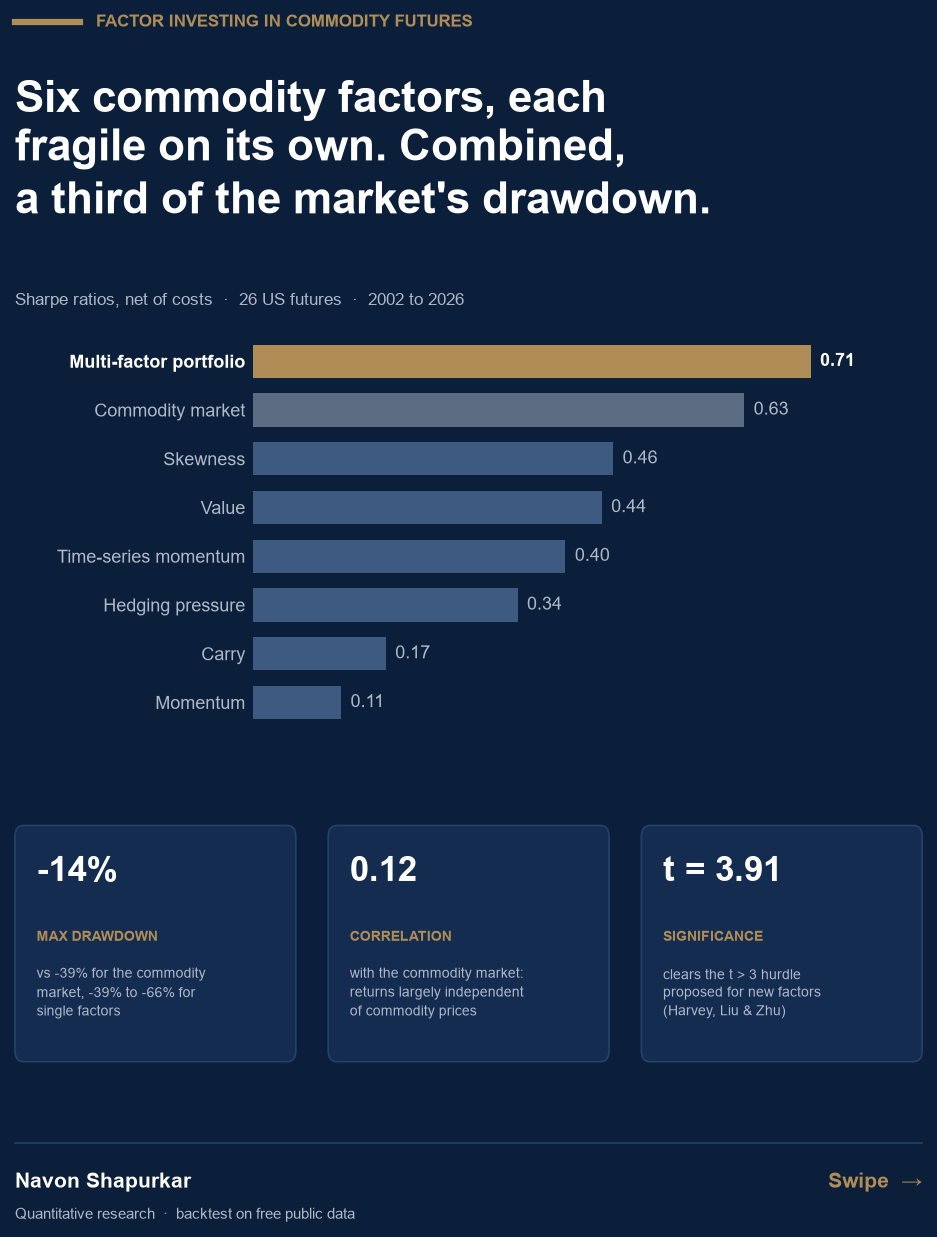

In [6]:
# ============================================================
# 06 · Cell 4 — Slide 1 (cover)
# ============================================================
from matplotlib.patches import FancyBboxPatch

white, soft, line, tile_fill = "#FFFFFF", "#AEB9C9", "#24426B", "#132C4F"

# Numbers for the cover (all computed from saved results)
cover_sharpe = final_summary["sharpe_net"].reindex(PRIMARY_FACTORS).copy()
cover_sharpe["EW_benchmark"] = sharpe["EW_benchmark"]
cover_sharpe["combo_equal_risk"] = sharpe["combo_equal_risk"]
cover_sharpe = cover_sharpe.sort_values()
single_dd = final_summary["max_dd_%"].reindex(PRIMARY_FACTORS)
cover_labels = {"EW_benchmark": "Commodity market", "combo_equal_risk": "Multi-factor portfolio"}

cover = plt.figure(figsize=STYLE.figsize, dpi=STYLE.dpi, facecolor=STYLE.navy)

# Header
cover.add_artist(plt.Line2D([0.08, 0.14], [0.935, 0.935], color=STYLE.accent, lw=3,
                            transform=cover.transFigure))
cover.text(0.155, 0.935, "FACTOR INVESTING IN COMMODITY FUTURES", fontsize=8, color=STYLE.accent,
           va="center", fontweight="bold")
cover.text(0.08, 0.895, "Six commodity factors, each\nfragile on its own. Combined,\n"
           "a third of the market's drawdown.", fontsize=21, fontweight="bold", color=white,
           va="top", linespacing=1.18)
cover.text(0.08, 0.735, "Sharpe ratios, net of costs  ·  26 US futures  ·  2002 to 2026",
           fontsize=8.4, color=soft, va="top")

# Hero chart: ranked Sharpe ratios
ax = cover.add_axes([0.30, 0.405, 0.62, 0.305])
ax.set_facecolor(STYLE.navy)
bar_colors = [STYLE.accent if k == "combo_equal_risk" else "#5B6B82" if k == "EW_benchmark" else "#3D5A80"
              for k in cover_sharpe.index]
ax.barh(range(len(cover_sharpe)), cover_sharpe.values, color=bar_colors, height=0.68)
for i, (key, value) in enumerate(cover_sharpe.items()):
    highlight = key == "combo_equal_risk"
    ax.text(value + 0.012, i, f"{value:.2f}", va="center", fontsize=8.5,
            color=white if highlight else soft, fontweight="bold" if highlight else "normal")
ax.set_yticks(range(len(cover_sharpe)))
ax.set_yticklabels([cover_labels.get(k, STYLE.label(k)) for k in cover_sharpe.index], fontsize=8.5)
for tick, key in zip(ax.get_yticklabels(), cover_sharpe.index):
    tick.set_color(white if key == "combo_equal_risk" else soft)
    tick.set_fontweight("bold" if key == "combo_equal_risk" else "normal")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0)
ax.set_xticks([])
ax.set_xlim(0, cover_sharpe.max() * 1.2)

# Context tiles
tiles = [
    (f"{max_dd['combo_equal_risk']:.0f}%", "max drawdown",
     f"vs {max_dd['EW_benchmark']:.0f}% for the commodity\nmarket, {single_dd.max():.0f}% to "
     f"{single_dd.min():.0f}% for\nsingle factors"),
    (f"{market_corr:.2f}", "correlation",
     "with the commodity market:\nreturns largely independent\nof commodity prices"),
    (f"t = {combo_t:.2f}", "significance",
     "clears the t > 3 hurdle\nproposed for new factors\n(Harvey, Liu & Zhu)"),
]
for i, (value, label, detail) in enumerate(tiles):
    x = 0.08 + i * 0.29
    cover.add_artist(FancyBboxPatch((x, 0.165), 0.26, 0.175, boxstyle="round,pad=0,rounding_size=0.008",
                                    transform=cover.transFigure, facecolor=tile_fill, edgecolor=line, lw=0.8))
    cover.text(x + 0.02, 0.318, value, fontsize=17, fontweight="bold", color=white, va="top")
    cover.text(x + 0.02, 0.262, label.upper(), fontsize=6.6, color=STYLE.accent, va="top", fontweight="bold")
    cover.text(x + 0.02, 0.237, detail, fontsize=6.9, color=soft, va="top", linespacing=1.4)

# Footer
cover.add_artist(plt.Line2D([0.08, 0.92], [0.105, 0.105], color=line, lw=0.8, transform=cover.transFigure))
cover.text(0.08, 0.083, AUTHOR, fontsize=10, fontweight="bold", color=white, va="top")
cover.text(0.08, 0.057, "Quantitative research  ·  backtest on free public data", fontsize=7.4,
           color=soft, va="top")
cover.text(0.92, 0.083, "Swipe  →", fontsize=10, fontweight="bold", color=STYLE.accent, ha="right", va="top")

cover_path = SLIDES_DIR / "01_cover.png"
cover.savefig(cover_path, dpi=STYLE.dpi, facecolor=STYLE.navy)
slides[1] = cover
print(f"Saved {cover_path.name}")
plt.show()

Saved 03_factor_scorecard.png


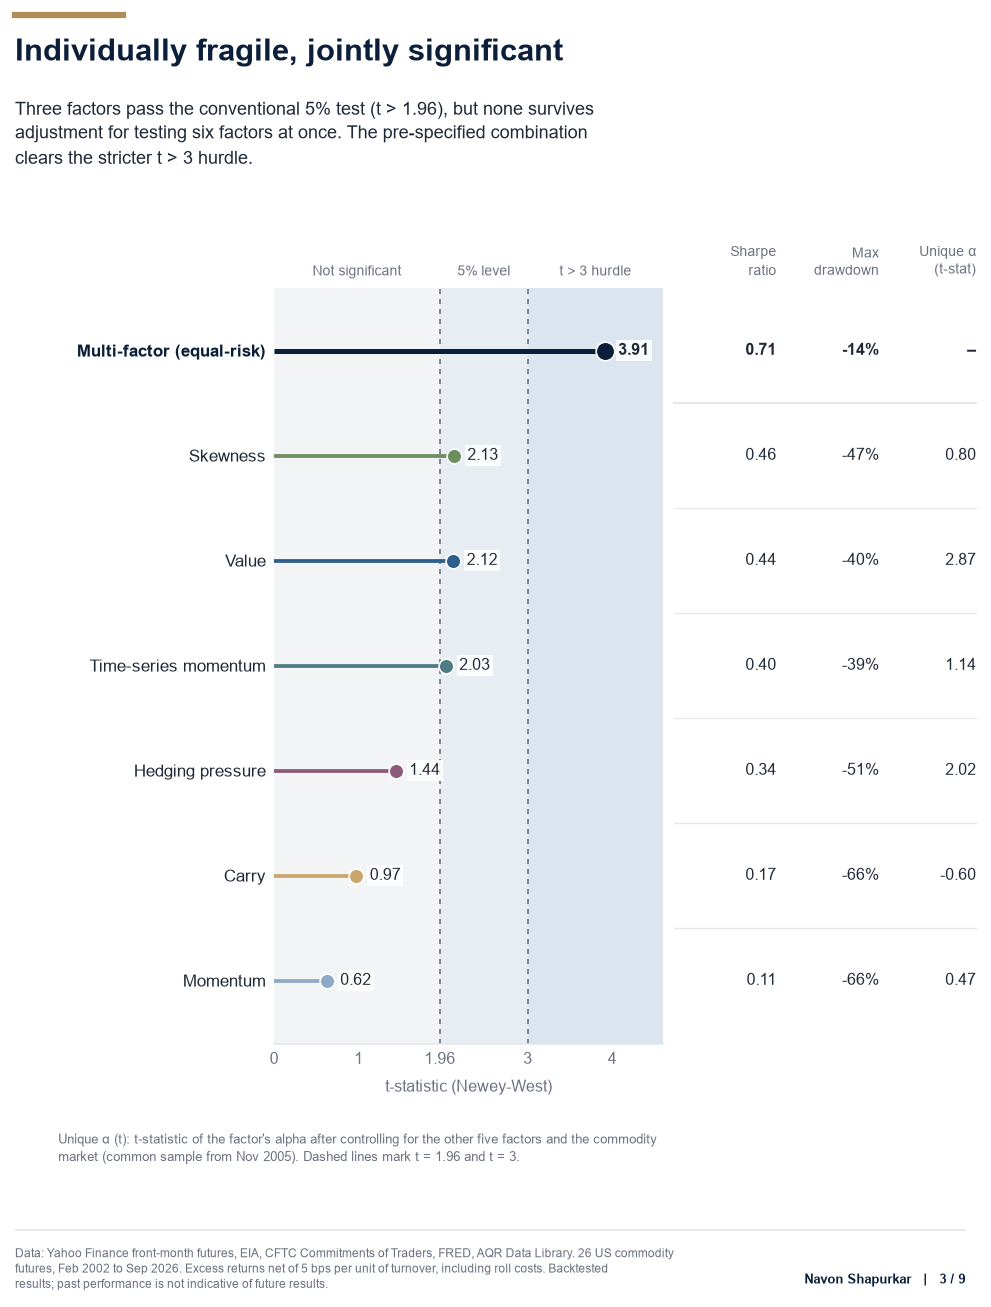

In [8]:
# ============================================================
# 06 · Cell 5 — Slide 3 (factor scorecard: statistical evidence)
# ============================================================
from matplotlib.transforms import blended_transform_factory

order = ["combo_equal_risk"] + (
    final_summary.drop("combo_equal_risk").sort_values("t_stat_nw", ascending=False).index.tolist()
)
score = final_summary.loc[order]
n_rows = len(score)
ys = np.arange(n_rows)[::-1]
T_MAX = 4.6
AX_LEFT, AX_BOTTOM, AX_WIDTH, AX_TOP = 0.30, 0.20, 0.36, 0.76

slide = new_slide(
    3,
    "Individually fragile, jointly significant",
    "Three factors pass the conventional 5% test (t > 1.96), but none survives adjustment for testing "
    "six factors at once. The pre-specified combination clears the stricter t > 3 hurdle.",
)
ax = slide.axes(rect=(AX_LEFT, AX_BOTTOM, AX_WIDTH, AX_TOP - AX_BOTTOM), grid_axis="")
above_axes = blended_transform_factory(ax.transData, ax.transAxes)

# Significance zones and thresholds
zones = [(0, 1.96, "#F3F4F6", "Not significant"), (1.96, 3.0, "#E8EDF3", "5% level"),
         (3.0, T_MAX, "#DCE5EF", "t > 3 hurdle")]
for low, high, colour, label in zones:
    ax.axvspan(low, high, color=colour, lw=0)
    ax.text((low + high) / 2, 1.012, label, transform=above_axes, ha="center", va="bottom",
            fontsize=6.8, color=STYLE.muted)
for x in (1.96, 3.0):
    ax.axvline(x, color=STYLE.muted, lw=0.8, ls=(0, (3, 3)))

# Lollipops with readable value labels
for y, (key, row) in zip(ys, score.iterrows()):
    is_combo = key == "combo_equal_risk"
    colour = STYLE.color(key)
    ax.hlines(y, 0, row["t_stat_nw"], color=colour, lw=2.4 if is_combo else 1.8)
    ax.scatter(row["t_stat_nw"], y, s=80 if is_combo else 50, color=colour, zorder=3,
               edgecolor="white", linewidth=0.8)
    ax.text(row["t_stat_nw"] + 0.16, y, f"{row['t_stat_nw']:.2f}", va="center", fontsize=7.6,
            color=STYLE.text, fontweight="bold" if is_combo else "normal", zorder=4,
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.2, "alpha": 0.9})

ax.set_yticks(ys)
ax.set_yticklabels([STYLE.label(k) for k in score.index], fontsize=8, color=STYLE.text)
ax.get_yticklabels()[0].set_fontweight("bold")
ax.get_yticklabels()[0].set_color(STYLE.navy)
ax.set_xlim(0, T_MAX)
ax.set_ylim(-0.6, n_rows - 0.4)
ax.set_xticks([0, 1, 1.96, 3, 4])
ax.set_xticklabels(["0", "1", "1.96", "3", "4"])
ax.spines["left"].set_visible(False)
ax.set_xlabel("t-statistic (Newey-West)", fontsize=7.5, color=STYLE.muted, labelpad=6)

# Table columns aligned to the rows
row_transform = blended_transform_factory(slide.fig.transFigure, ax.transData)
header_y = AX_TOP + 0.012 * (AX_TOP - AX_BOTTOM)
table_columns = [
    ("Sharpe\nratio", 0.765, lambda r: f"{r['sharpe_net']:.2f}"),
    ("Max\ndrawdown", 0.86, lambda r: f"{r['max_dd_%']:.0f}%"),
    ("Unique α\n(t-stat)", 0.95,
     lambda r: "–" if pd.isna(r["alpha_vs_factors_t"]) else f"{r['alpha_vs_factors_t']:.2f}"),
]
for header, x, fmt in table_columns:
    slide.fig.text(x, header_y, header, ha="right", va="bottom", fontsize=6.8, color=STYLE.muted,
                   linespacing=1.3)
    for y, (key, row) in zip(ys, score.iterrows()):
        slide.fig.text(x, y, fmt(row), transform=row_transform, ha="right", va="center", fontsize=7.8,
                       color=STYLE.text, fontweight="bold" if key == "combo_equal_risk" else "normal")

# Row separators (heavier under the combination)
for y in ys[:-1]:
    line_y = ax.transData.transform((0, y - 0.5))[1] / slide.fig.bbox.height
    slide.fig.add_artist(plt.Line2D([AX_LEFT + AX_WIDTH + 0.01, 0.95], [line_y, line_y],
                                    color=STYLE.grid, lw=1.0 if y == ys[0] else 0.6,
                                    transform=slide.fig.transFigure))

slide.fig.text(
    0.10, 0.135,
    "Unique α (t): t-statistic of the factor's alpha after controlling for the other five factors and the "
    "commodity\nmarket (common sample from Nov 2005). Dashed lines mark t = 1.96 and t = 3.",
    fontsize=6.4, color=STYLE.muted, va="top", linespacing=1.4,
)

path = slide.save(SLIDES_DIR, "03_factor_scorecard")
slides[3] = slide.fig
print(f"Saved {path.name}")
plt.show()

Saved 04_correlations.png


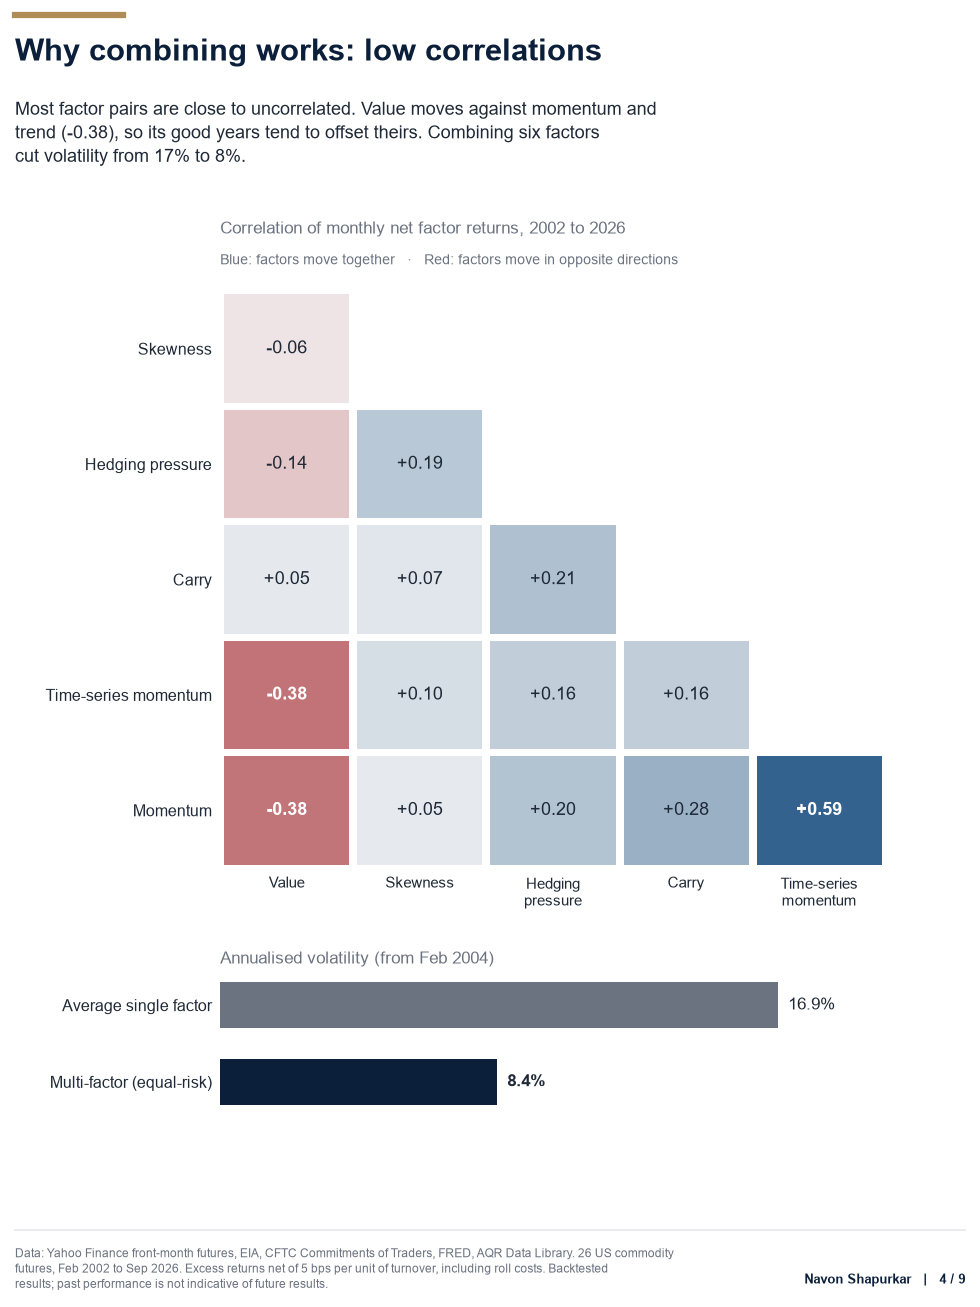

In [9]:
# ============================================================
# 06 · Cell 6 — Slide 4 (why combining works: correlations)
# ============================================================
from matplotlib.colors import LinearSegmentedColormap

CORR_ORDER = ["value", "skewness", "hedging_pressure", "carry", "tsmom_12", "mom_12_1"]
corr = factor_returns[CORR_ORDER].corr()

combo_start = combos.index.min()
avg_factor_vol = factor_returns.loc[combo_start:].std().mean() * np.sqrt(12) * 100
combo_vol = combos["combo_equal_risk"].std() * np.sqrt(12) * 100
value_vs_trend = corr.loc["value", ["mom_12_1", "tsmom_12"]]

slide = new_slide(
    4,
    "Why combining works: low correlations",
    f"Most factor pairs are close to uncorrelated. Value moves against momentum and trend "
    f"({value_vs_trend.min():+.2f}), so its good years tend to offset theirs. Combining six factors cut "
    f"volatility from {avg_factor_vol:.0f}% to {combo_vol:.0f}%.",
)
slide.fig.text(0.25, 0.80, "Correlation of monthly net factor returns, 2002 to 2026", fontsize=8,
               color=STYLE.muted)
slide.fig.text(0.25, 0.785, "Blue: factors move together   ·   Red: factors move in opposite directions",
               fontsize=6.6, color=STYLE.muted, va="top")

# 1. Lower-triangle correlation matrix
ax = slide.axes(rect=(0.25, 0.33, 0.62, 0.43), grid_axis="")
cmap = LinearSegmentedColormap.from_list("factor_corr", [STYLE.negative, "#F7F7F7", STYLE.color("value")])
rows, cols, n = CORR_ORDER[1:], CORR_ORDER[:-1], len(CORR_ORDER)

for i, row in enumerate(rows):
    for j, col in enumerate(cols):
        if j > i:
            continue
        value = corr.loc[row, col]
        strong = abs(value) > 0.33
        ax.add_patch(plt.Rectangle((j, n - 2 - i), 0.94, 0.94, color=cmap((value + 0.6) / 1.2), lw=0))
        ax.text(j + 0.47, n - 2 - i + 0.47, f"{value:+.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if strong else STYLE.text, fontweight="bold" if strong else "normal")

ax.set_xlim(-0.03, n - 1)
ax.set_ylim(-0.03, n - 1)
ax.set_xticks(np.arange(n - 1) + 0.47)
ax.set_xticklabels([STYLE.label(c).replace(" ", "\n", 1) if len(STYLE.label(c)) > 10 else STYLE.label(c)
                    for c in cols], fontsize=7.4, color=STYLE.text)
ax.set_yticks(np.arange(n - 1)[::-1] + 0.47)
ax.set_yticklabels([STYLE.label(r) for r in rows], fontsize=7.8, color=STYLE.text)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0)

# 2. Volatility: average single factor vs combination
ax_vol = slide.axes(rect=(0.25, 0.15, 0.62, 0.10), grid_axis="")
bars = [("Average single factor", avg_factor_vol, STYLE.muted),
        ("Multi-factor (equal-risk)", combo_vol, STYLE.navy)]
for k, (label, value, colour) in enumerate(bars):
    ax_vol.barh(1 - k, value, color=colour, height=0.6)
    ax_vol.text(value + 0.3, 1 - k, f"{value:.1f}%", va="center", fontsize=8, color=STYLE.text,
                fontweight="bold" if k else "normal")
ax_vol.set_yticks([1, 0])
ax_vol.set_yticklabels([b[0] for b in bars], fontsize=7.8, color=STYLE.text)
ax_vol.set_xlim(0, avg_factor_vol * 1.2)
ax_vol.set_xticks([])
for spine in ax_vol.spines.values():
    spine.set_visible(False)
ax_vol.tick_params(length=0)
ax_vol.set_title(f"Annualised volatility (from {combo_start:%b %Y})", loc="left", fontsize=8,
                 color=STYLE.muted)

path = slide.save(SLIDES_DIR, "04_correlations")
slides[4] = slide.fig
print(f"Saved {path.name}")
plt.show()

Saved 05_crisis_behaviour.png
                  GFC crash\nJul 2008 to Feb 2009  Oil collapse\nJul 2014 to Jan 2016  COVID crash\nJan to Apr 2020  Worst 10% of\nmarket months
EW_benchmark                                -39.1                               -26.9                         -16.3                         -6.1
combo_equal_risk                              5.9                                -0.1                          -5.5                         -0.4
value                                        31.0                                 4.3                         -28.2                          1.0
hedging_pressure                             47.9                               -12.9                          -8.9                          0.4
skewness                                     -4.2                                -5.8                          30.4                          0.2
tsmom_12                                    -13.2                                12.6               

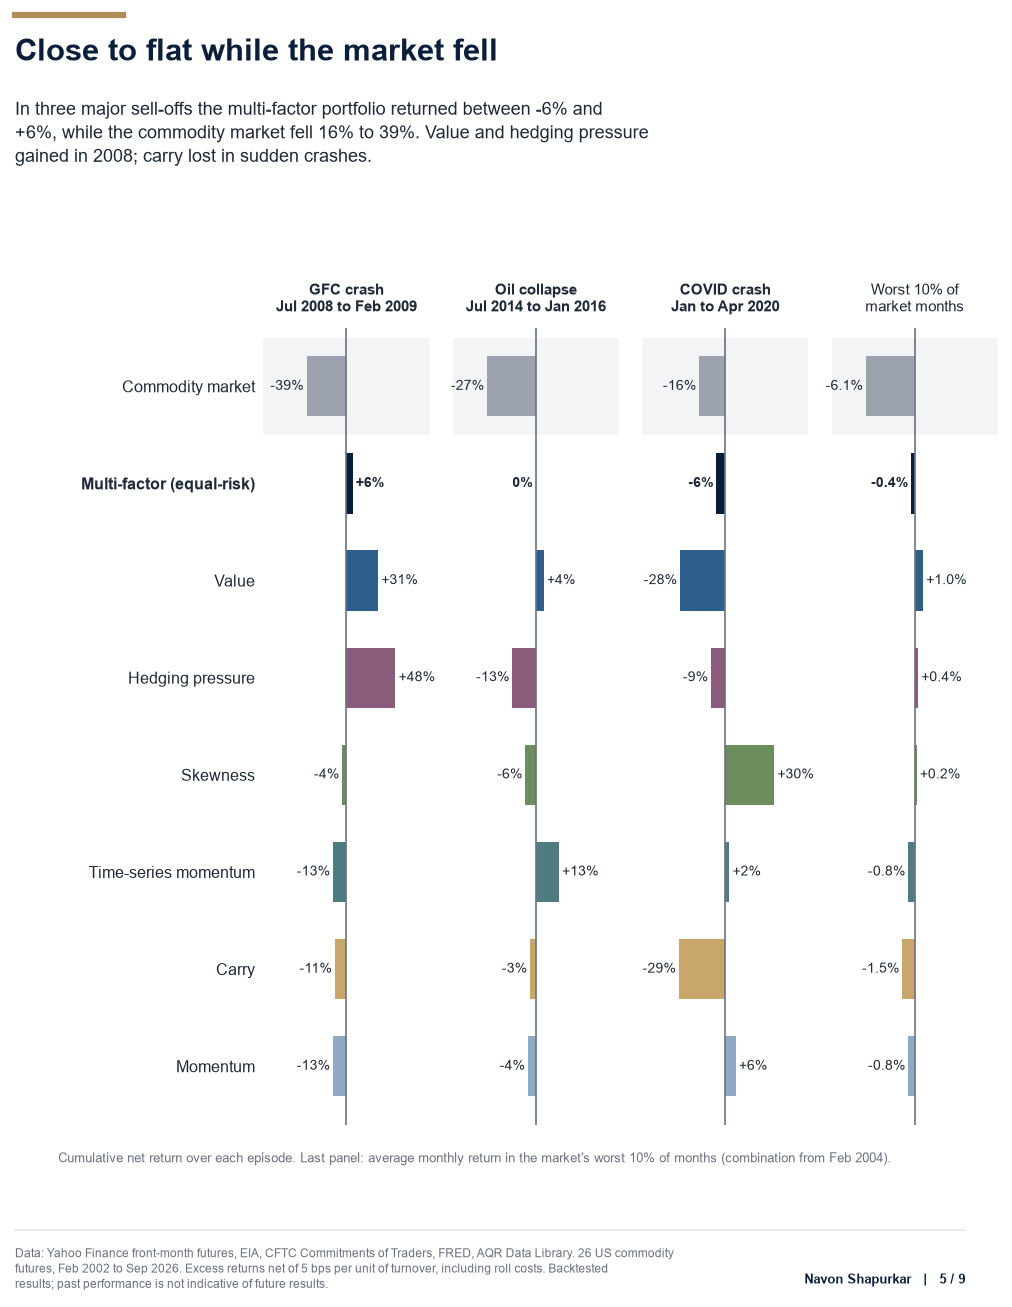

In [11]:
# ============================================================
# 06 · Cell 7 — Slide 5 (crisis behaviour)
# ============================================================
from commodity_factors.viz import style_axes

EPISODES = {
    "GFC crash (2008-07 to 2009-02)": ("GFC crash\nJul 2008 to Feb 2009", "2008-07", "2009-02"),
    "Oil collapse (2014-07 to 2016-01)": ("Oil collapse\nJul 2014 to Jan 2016", "2014-07", "2016-01"),
    "COVID crash (2020-01 to 2020-04)": ("COVID crash\nJan to Apr 2020", "2020-01", "2020-04"),
}
ROWS = ["EW_benchmark", "combo_equal_risk", "value", "hedging_pressure", "skewness", "tsmom_12", "carry", "mom_12_1"]
ROW_LABELS = {**{k: STYLE.label(k) for k in ROWS}, "EW_benchmark": "Commodity market"}

# Episode returns: notebook 04 table for factors and market, combination computed here
crisis = pd.DataFrame(index=ROWS)
for source_label, (label, start, end) in EPISODES.items():
    column = event_study.loc[source_label].reindex(ROWS)
    column["combo_equal_risk"] = ((1 + combos["combo_equal_risk"].loc[start:end]).prod() - 1) * 100
    crisis[label] = column

# Average monthly return in the market's worst 10% of months (same definition as notebook 04)
tail_frame = factor_returns.copy()
tail_frame["EW_benchmark"] = benchmarks["EW_all"].reindex(tail_frame.index)
tail_frame["combo_equal_risk"] = combos["combo_equal_risk"].reindex(tail_frame.index)
worst_months = tail_frame["EW_benchmark"] <= tail_frame["EW_benchmark"].quantile(0.10)
crisis["Worst 10% of\nmarket months"] = tail_frame.loc[worst_months, ROWS].mean() * 100

# Slide: lead with the combination's behaviour
episode_cols = crisis.columns[:3]
combo_range = crisis.loc["combo_equal_risk", episode_cols]
market_range = crisis.loc["EW_benchmark", episode_cols].abs()
slide = new_slide(
    5,
    "Close to flat while the market fell",
    f"In three major sell-offs the multi-factor portfolio returned between {combo_range.min():+.0f}% and "
    f"{combo_range.max():+.0f}%, while the commodity market fell {market_range.min():.0f}% to "
    f"{market_range.max():.0f}%. Value and hedging pressure gained in 2008; carry lost in sudden crashes.",
)

grid = slide.fig.add_gridspec(1, 4, left=0.29, right=0.97, top=0.73, bottom=0.14, wspace=0.14)
axes = [style_axes(slide.fig.add_subplot(cell), STYLE, "") for cell in grid]
ys = np.arange(len(ROWS))[::-1]

for k, (ax, column) in enumerate(zip(axes, crisis.columns)):
    values = crisis[column]
    limit = max(values.abs().max() * 1.7, 1)
    is_tail_panel = k == len(crisis.columns) - 1
    ax.axhspan(len(ROWS) - 1.5, len(ROWS) - 0.5, color="#F3F4F6", lw=0, zorder=0)
    for y, (key, value) in zip(ys, values.items()):
        ax.barh(y, value, color=STYLE.color(key), height=0.62)
        offset = limit * 0.04 if value >= 0 else -limit * 0.04
        decimals = 1 if is_tail_panel else 0
        text = "0%" if round(value, decimals) == 0 else f"{value:+.{decimals}f}%"
        ax.text(value + offset, y, text, va="center", ha="left" if value >= 0 else "right",
                fontsize=6.6, color=STYLE.text, fontweight="bold" if key == "combo_equal_risk" else "normal")
    ax.axvline(0, color=STYLE.muted, lw=0.8)
    ax.set_xlim(-limit, limit)
    ax.set_xticks([])
    ax.set_ylim(-0.6, len(ROWS) - 0.4)
    ax.set_title(column, fontsize=7.4, color=STYLE.text, pad=8,
                 fontweight="normal" if is_tail_panel else "bold")
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_yticks(ys)
    ax.set_yticklabels([ROW_LABELS[r] for r in ROWS] if k == 0 else [], fontsize=7.6, color=STYLE.text)
    ax.tick_params(length=0)
axes[0].get_yticklabels()[1].set_fontweight("bold")

slide.fig.text(0.10, 0.112, "Cumulative net return over each episode. Last panel: average monthly return in the "
               "market's worst 10% of months (combination from Feb 2004).", fontsize=6.4, color=STYLE.muted)

path = slide.save(SLIDES_DIR, "05_crisis_behaviour")
slides[5] = slide.fig
print(f"Saved {path.name}")
print(crisis.round(1).to_string())
plt.show()

Saved 06_regimes.png | significant cells: 1 of 36


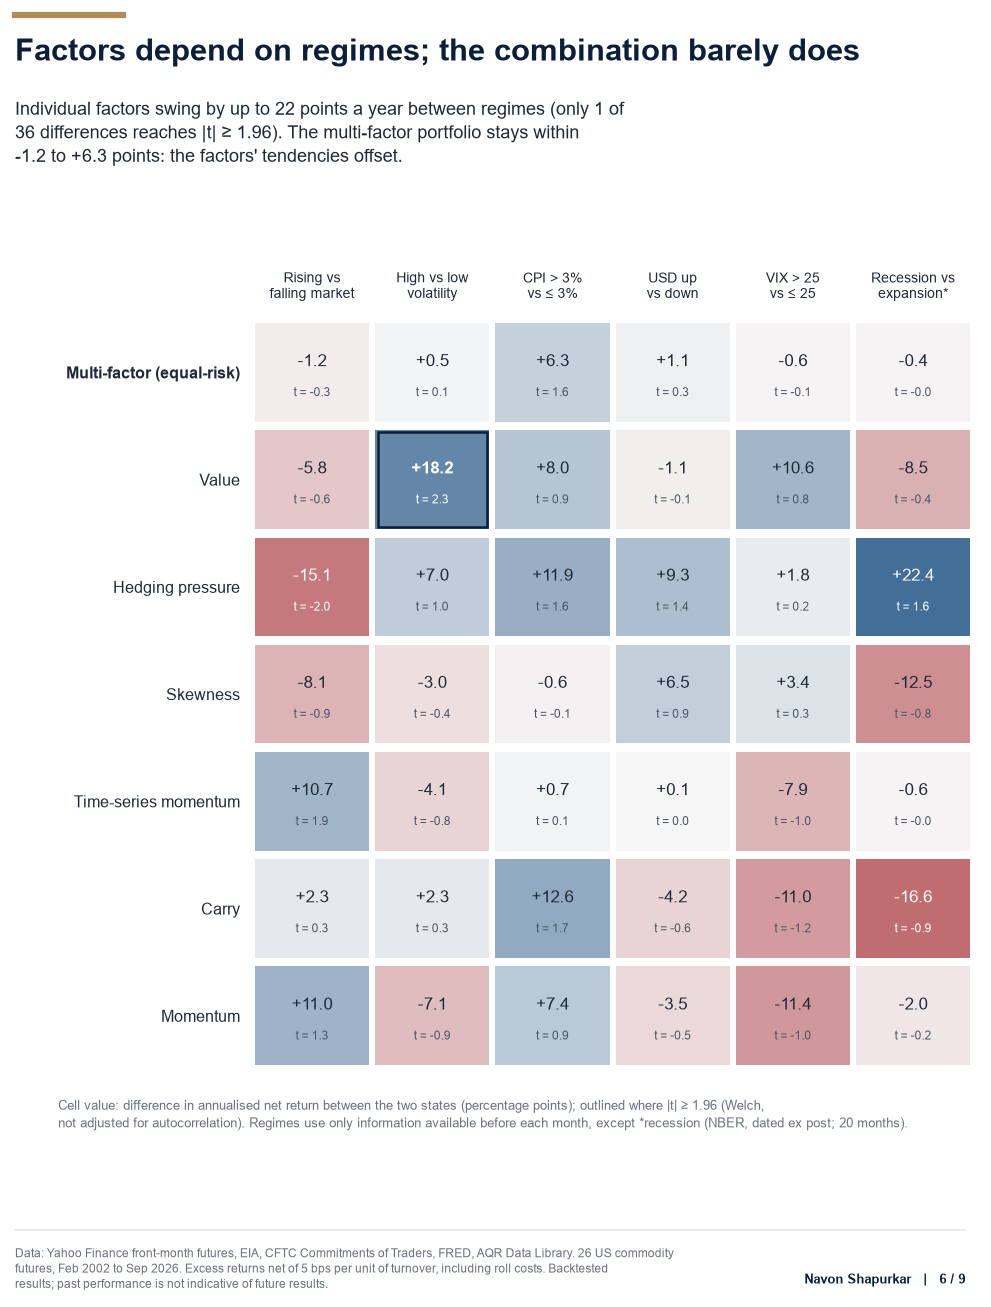

In [13]:
# ============================================================
# 06 · Cell 8 — Slide 6 (regime heatmap)
# ============================================================
from matplotlib.colors import LinearSegmentedColormap

REGIME_COLUMNS = {
    "commodity_rising": "Rising vs\nfalling market",
    "commodity_high_vol": "High vs low\nvolatility",
    "inflation_high": "CPI > 3%\nvs ≤ 3%",
    "dollar_strengthening": "USD up\nvs down",
    "equity_stress_vix25": "VIX > 25\nvs ≤ 25",
    "recession_ex_post": "Recession vs\nexpansion*",
}
REGIME_ROWS = ["combo_equal_risk", "value", "hedging_pressure", "skewness", "tsmom_12", "carry", "mom_12_1"]
regimes = load("regimes")


def regime_split(returns: pd.Series, state: pd.Series) -> tuple[float, float]:
    """Annualised return difference (TRUE - FALSE) and Welch t-statistic."""
    data = pd.concat([returns, state], axis=1, keys=["r", "s"], sort=True).dropna()
    on, off = data.loc[data["s"] > 0.5, "r"], data.loc[data["s"] <= 0.5, "r"]
    diff = on.mean() - off.mean()
    return diff * 1200, diff / np.sqrt(on.var() / len(on) + off.var() / len(off))


diff_grid = pd.DataFrame(index=REGIME_ROWS, columns=list(REGIME_COLUMNS), dtype=float)
t_grid = diff_grid.copy()
for regime in REGIME_COLUMNS:
    for factor in REGIME_ROWS[1:]:
        diff_grid.at[factor, regime] = regime_table.at[(regime, factor), "diff_%"]
        t_grid.at[factor, regime] = regime_table.at[(regime, factor), "t_diff"]
    diff_grid.at["combo_equal_risk", regime], t_grid.at["combo_equal_risk", regime] = regime_split(
        combos["combo_equal_risk"], regimes[regime]
    )

factor_diffs = diff_grid.drop("combo_equal_risk")
combo_diffs = diff_grid.loc["combo_equal_risk"]
n_significant = int((t_grid.drop("combo_equal_risk").abs() >= 1.96).sum().sum())
n_tests = factor_diffs.size

slide = new_slide(
    6,
    "Factors depend on regimes; the combination barely does",
    f"Individual factors swing by up to {factor_diffs.abs().max().max():.0f} points a year between regimes "
    f"(only {n_significant} of {n_tests} differences reaches |t| ≥ 1.96). The multi-factor portfolio stays "
    f"within {combo_diffs.min():+.1f} to {combo_diffs.max():+.1f} points: the factors' tendencies offset.",
)
ax = slide.axes(rect=(0.28, 0.18, 0.67, 0.56), grid_axis="")
cmap = LinearSegmentedColormap.from_list("regime", [STYLE.negative, "#F7F7F7", STYLE.color("value")])
limit = 25
detail_grey = "#4B5563"

for i, factor in enumerate(REGIME_ROWS):
    for j, regime in enumerate(REGIME_COLUMNS):
        value, t_value = diff_grid.at[factor, regime], t_grid.at[factor, regime]
        y = len(REGIME_ROWS) - 1 - i
        strong, significant = abs(value) > 0.55 * limit, abs(t_value) >= 1.96
        ax.add_patch(plt.Rectangle((j, y), 0.95, 0.92, lw=0,
                                   color=cmap((np.clip(value, -limit, limit) + limit) / (2 * limit))))
        ax.text(j + 0.475, y + 0.56, f"{value:+.1f}", ha="center", va="center", fontsize=8.2,
                color="white" if strong else STYLE.text, fontweight="bold" if significant else "normal")
        ax.text(j + 0.475, y + 0.27, f"t = {t_value:.1f}", ha="center", va="center", fontsize=5.8,
                color="white" if strong else detail_grey)
        if significant:
            ax.add_patch(plt.Rectangle((j + 0.02, y + 0.02), 0.91, 0.88, fill=False, ec=STYLE.navy, lw=1.2))

ax.set_xlim(-0.02, len(REGIME_COLUMNS))
ax.set_ylim(-0.05, len(REGIME_ROWS))
ax.set_xticks(np.arange(len(REGIME_COLUMNS)) + 0.475)
ax.set_xticklabels(list(REGIME_COLUMNS.values()), fontsize=6.8, color=STYLE.text)
ax.xaxis.tick_top()
ax.set_yticks(np.arange(len(REGIME_ROWS))[::-1] + 0.46)
ax.set_yticklabels([STYLE.label(r) for r in REGIME_ROWS], fontsize=7.8, color=STYLE.text)
ax.get_yticklabels()[0].set_fontweight("bold")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0, pad=6)

slide.fig.text(
    0.10, 0.160,
    "Cell value: difference in annualised net return between the two states (percentage points); outlined "
    "where |t| ≥ 1.96 (Welch,\nnot adjusted for autocorrelation). Regimes use only information available "
    "before each month, except *recession (NBER, dated ex post; 20 months).",
    fontsize=6.2, color=STYLE.muted, va="top", linespacing=1.45,
)

path = slide.save(SLIDES_DIR, "06_regimes")
slides[6] = slide.fig
print(f"Saved {path.name} | significant cells: {n_significant} of {n_tests}")
plt.show()

Saved 07_aqr_validation.png


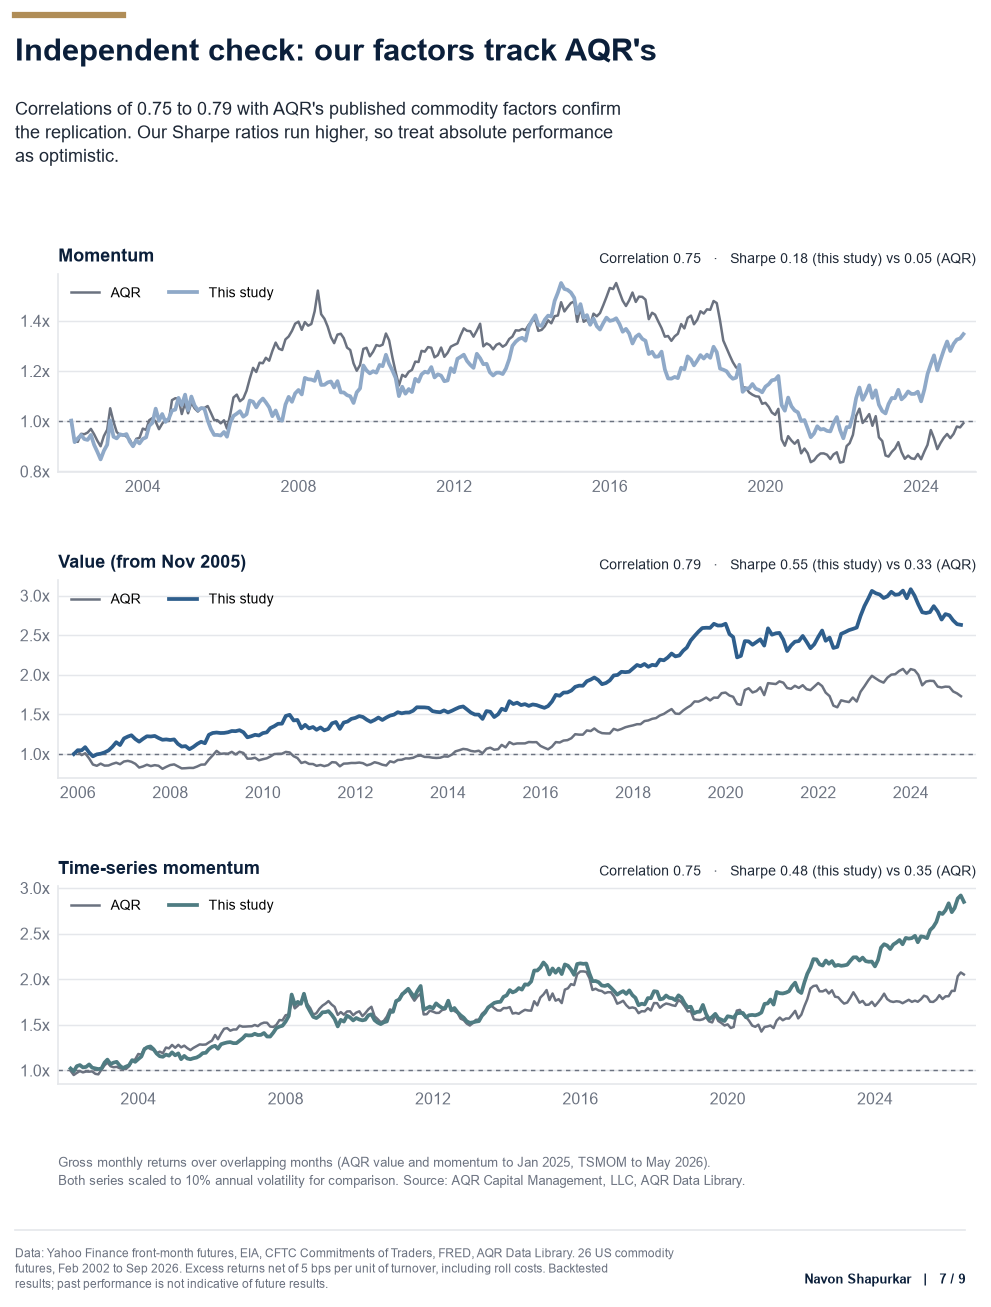

In [17]:
# ============================================================
# 06 · Cell 9 — Slide 7 (independent validation against AQR)
# ============================================================
from datetime import datetime

from matplotlib.ticker import FuncFormatter, MultipleLocator

from commodity_factors.viz import style_axes

AQR_DIR = PATHS.raw / "aqr"
AQR_SOURCES = {
    "mom_12_1": ("Value-and-Momentum-Everywhere-Factors-Monthly.xlsx", "MOMLS_VME_COM", "mom_12_1 vs aqr_momentum"),
    "value": ("Value-and-Momentum-Everywhere-Factors-Monthly.xlsx", "VALLS_VME_COM", "value vs aqr_value"),
    "tsmom_12": ("Time-Series-Momentum-Factors-Monthly.xlsx", "TSMOM^CM", "tsmom_12 vs aqr_tsmom"),
}
TARGET_VOL = 0.10
factor_gross = load("factor_returns_gross")


def to_timestamp(value):
    if isinstance(value, (pd.Timestamp, datetime)):
        return pd.Timestamp(value)
    if isinstance(value, str):
        try:
            return pd.Timestamp(datetime.strptime(value.strip(), "%m/%d/%Y"))
        except ValueError:
            return None
    return None


def read_aqr(path: Path) -> pd.DataFrame:
    """Monthly returns from the workbook's 'Factors' sheet, indexed by month-end."""
    workbook = pd.ExcelFile(path)
    sheet = next(s for s in workbook.sheet_names if "factors" in s.lower())
    raw = pd.read_excel(workbook, sheet_name=sheet, header=None)
    dates = raw.iloc[:, 0].map(to_timestamp)
    first_row = int(dates.notna().to_numpy().argmax())
    columns = raw.iloc[first_row - 1].astype(str).str.strip().tolist()
    columns[0] = "date"
    frame = raw.iloc[first_row:].copy()
    frame.columns = columns
    frame["date"] = dates.iloc[first_row:]
    frame = frame.dropna(subset=["date"])
    frame.index = pd.DatetimeIndex(frame.pop("date")) + pd.offsets.MonthEnd(0)
    return frame.apply(pd.to_numeric, errors="coerce")


workbooks = {name: read_aqr(AQR_DIR / name) for name in {src[0] for src in AQR_SOURCES.values()}}
correlations = aqr_validation["correlation"]

slide = new_slide(
    7,
    "Independent check: our factors track AQR's",
    f"Correlations of {correlations.min():.2f} to {correlations.max():.2f} with AQR's published commodity "
    "factors confirm the replication. Our Sharpe ratios run higher, so treat absolute performance as optimistic.",
)
grid = slide.fig.add_gridspec(3, 1, left=0.10, right=0.95, top=0.77, bottom=0.17, hspace=0.55)
axes = [style_axes(slide.fig.add_subplot(cell), STYLE, "y") for cell in grid]

for ax, (factor, (file_name, column, table_row)) in zip(axes, AQR_SOURCES.items()):
    both = pd.concat({"ours": factor_gross[factor], "aqr": workbooks[file_name][column]}, axis=1,
                     sort=True).dropna()
    scaled = both / both.std() * TARGET_VOL / np.sqrt(12)
    wealth = (1 + scaled).cumprod()

    ax.axhline(1, color=STYLE.muted, lw=0.7, ls=(0, (3, 3)), zorder=1)
    ax.plot(wealth["aqr"], color=STYLE.muted, lw=1.2, label="AQR", zorder=2)
    ax.plot(wealth["ours"], color=STYLE.color(factor), lw=1.8, label="This study", zorder=3)

    padding = pd.DateOffset(months=4)
    ax.set_xlim(wealth.index.min() - padding, wealth.index.max() + padding)

    # Tick steps chosen so 1.0x (break-even) is always labelled
    span = wealth.max().max() - min(wealth.min().min(), 1.0)
    step = 0.2 if span < 1.0 else 0.5 if span < 2.5 else 1.0
    ax.yaxis.set_major_locator(MultipleLocator(step))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.1f}x"))
    ax.legend(loc="upper left", ncol=2, fontsize=6.8)

    starts_late = wealth.index.min() > factor_returns.index.min() + pd.DateOffset(months=6)
    title = f"{STYLE.label(factor)} (from {wealth.index.min():%b %Y})" if starts_late else STYLE.label(factor)
    ax.set_title(title, loc="left", fontsize=8.6, fontweight="bold", color=STYLE.navy)

    row = aqr_validation.loc[table_row]
    ax.text(1.0, 1.04, f"Correlation {row['correlation']:.2f}   ·   Sharpe {row['our_sharpe']:.2f} (this study) "
            f"vs {row['aqr_sharpe']:.2f} (AQR)", transform=ax.transAxes, ha="right", va="bottom",
            fontsize=6.8, color=STYLE.text)

slide.fig.text(
    0.10, 0.118,
    "Gross monthly returns over overlapping months (AQR value and momentum to Jan 2025, TSMOM to May 2026).\n"
    "Both series scaled to 10% annual volatility for comparison. Source: AQR Capital Management, LLC, AQR Data Library.",
    fontsize=6.4, color=STYLE.muted, va="top", linespacing=1.45,
)

path = slide.save(SLIDES_DIR, "07_aqr_validation")
slides[7] = slide.fig
print(f"Saved {path.name}")
plt.show()

Saved 08_long_only_tilt.png


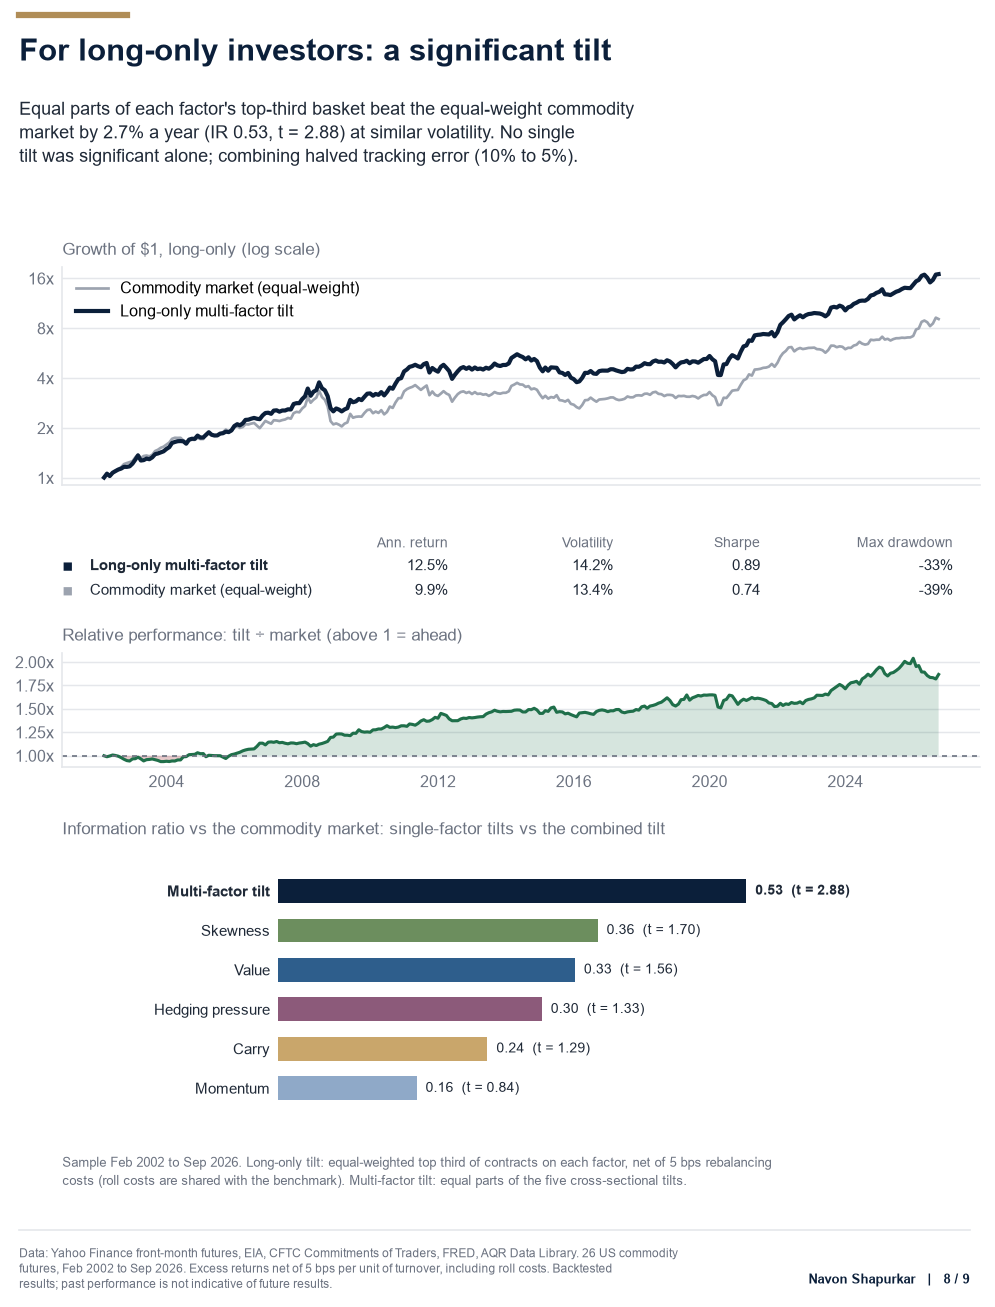

In [21]:
# ============================================================
# 06 · Cell 10 — Slide 8 (long-only multi-factor tilt vs the market)
# ============================================================
from matplotlib.ticker import FuncFormatter, MultipleLocator, NullLocator

from commodity_factors.viz import style_axes

# Data: tilt return = market return + excess return over the market
single_tilts = load("long_only_excess")
tilt_ir = (single_tilts.mean() / single_tilts.std() * np.sqrt(12)).sort_values()
tilt_t = single_tilts.apply(newey_west_tstat)
single_te = single_tilts.std().mean() * np.sqrt(12) * 100

combo_excess = long_only_combo.dropna()
market = benchmarks["EW_all"].reindex(combo_excess.index)
tilt = market + combo_excess
combo_ir = combo_excess.mean() / combo_excess.std() * np.sqrt(12)
combo_t_lo = newey_west_tstat(combo_excess)
combo_ann = combo_excess.mean() * 1200
combo_te = combo_excess.std() * np.sqrt(12) * 100


def strip_stats(r: pd.Series) -> list[str]:
    wealth = (1 + r).cumprod()
    vol = r.std() * np.sqrt(12)
    return [f"{r.mean() * 1200:.1f}%", f"{vol * 100:.1f}%", f"{r.mean() * 12 / vol:.2f}",
            f"{(wealth / wealth.cummax() - 1).min() * 100:.0f}%"]


slide = new_slide(
    8,
    "For long-only investors: a significant tilt",
    f"Equal parts of each factor's top-third basket beat the equal-weight commodity market by {combo_ann:.1f}% "
    f"a year (IR {combo_ir:.2f}, t = {combo_t_lo:.2f}) at similar volatility. No single tilt was significant "
    f"alone; combining halved tracking error ({single_te:.0f}% to {combo_te:.0f}%).",
)

grid = slide.fig.add_gridspec(3, 1, left=0.10, right=0.95, top=0.775, bottom=0.405, hspace=0.42,
                              height_ratios=[2.3, 0.62, 1.2])
ax_abs = style_axes(slide.fig.add_subplot(grid[0]), STYLE, "y")
ax_table = slide.fig.add_subplot(grid[1])
ax_rel = style_axes(slide.fig.add_subplot(grid[2]), STYLE, "y")

# 1. Absolute growth: tilt vs market (ticks limited to the data's range)
wealth_tilt, wealth_market = (1 + tilt).cumprod(), (1 + market).cumprod()
ax_abs.plot(wealth_market, color=STYLE.color("EW_benchmark"), lw=1.3, label=STYLE.label("EW_benchmark"))
ax_abs.plot(wealth_tilt, color=STYLE.navy, lw=2.0, label="Long-only multi-factor tilt")
ax_abs.set_yscale("log")
ax_abs.yaxis.set_minor_locator(NullLocator())
low_value = min(wealth_tilt.min(), wealth_market.min()) * 0.9
high_value = max(wealth_tilt.max(), wealth_market.max()) * 1.1
ax_abs.set_yticks([t for t in [0.5, 1, 2, 4, 8, 16, 32] if low_value <= t <= high_value])
ax_abs.set_ylim(low_value, high_value)
ax_abs.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}x"))
ax_abs.legend(loc="upper left")
ax_abs.tick_params(labelbottom=False)
ax_abs.set_title("Growth of $1, long-only (log scale)", loc="left", fontsize=8, color=STYLE.muted)

# 2. Statistics strip
ax_table.axis("off")
headers, xs = ["Ann. return", "Volatility", "Sharpe", "Max drawdown"], [0.42, 0.60, 0.76, 0.97]
for x, header in zip(xs, headers):
    ax_table.text(x, 1.05, header, ha="right", va="top", fontsize=6.8, color=STYLE.muted,
                  transform=ax_table.transAxes)
rows = [("Long-only multi-factor tilt", tilt, STYLE.navy),
        (STYLE.label("EW_benchmark"), market, STYLE.color("EW_benchmark"))]
for i, (label, series, colour) in enumerate(rows):
    y = 0.55 - i * 0.42
    ax_table.text(0, y, "■", color=colour, fontsize=8.5, va="center", transform=ax_table.transAxes)
    ax_table.text(0.03, y, label, fontsize=7.3, va="center", color=STYLE.text,
                  fontweight="bold" if i == 0 else "normal", transform=ax_table.transAxes)
    for x, value in zip(xs, strip_stats(series)):
        ax_table.text(x, y, value, ha="right", va="center", fontsize=7.4, color=STYLE.text,
                      transform=ax_table.transAxes)

# 3. Relative performance: tilt / market
relative = wealth_tilt / wealth_market
ax_rel.fill_between(relative.index, relative, 1, where=relative >= 1, color=STYLE.positive, alpha=0.18,
                    lw=0, interpolate=True)
ax_rel.fill_between(relative.index, relative, 1, where=relative < 1, color=STYLE.negative, alpha=0.25,
                    lw=0, interpolate=True)
ax_rel.plot(relative, color=STYLE.positive, lw=1.5)
ax_rel.axhline(1, color=STYLE.muted, lw=0.8, ls=(0, (3, 3)))
ax_rel.yaxis.set_major_locator(MultipleLocator(0.25))
ax_rel.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.2f}x"))
ax_rel.set_xlim(ax_abs.get_xlim())
ax_rel.set_title("Relative performance: tilt ÷ market (above 1 = ahead)", loc="left", fontsize=8,
                 color=STYLE.muted)

# 4. Information ratio: single tilts vs combined
ax_ir = style_axes(slide.fig.add_axes([0.30, 0.15, 0.65, 0.18]), STYLE, "")
labels = [STYLE.label(k) for k in tilt_ir.index] + ["Multi-factor tilt"]
values = list(tilt_ir.values) + [combo_ir]
t_values = list(tilt_t.reindex(tilt_ir.index).values) + [combo_t_lo]
colours = [STYLE.color(k) for k in tilt_ir.index] + [STYLE.navy]
ys = np.arange(len(values))
ax_ir.barh(ys, values, color=colours, height=0.6)
for y, value, t_value in zip(ys, values, t_values):
    ax_ir.text(value + 0.01, y, f"{value:.2f}  (t = {t_value:.2f})", va="center", fontsize=6.9,
               color=STYLE.text, fontweight="bold" if y == len(values) - 1 else "normal")
ax_ir.set_yticks(ys)
ax_ir.set_yticklabels(labels, fontsize=7.3, color=STYLE.text)
ax_ir.get_yticklabels()[-1].set_fontweight("bold")
ax_ir.set_xlim(0, max(values) * 1.5)
ax_ir.set_xticks([])
for spine in ax_ir.spines.values():
    spine.set_visible(False)
ax_ir.tick_params(length=0)

# Captions
caption = "Information ratio vs the commodity market: single-factor tilts vs the combined tilt"
slide.fig.text(0.10, 0.355, caption, fontsize=8, color=STYLE.muted)
note = (
    f"Sample {tilt.index.min():%b %Y} to {tilt.index.max():%b %Y}. Long-only tilt: equal-weighted top third "
    "of contracts on each factor, net of 5 bps rebalancing\ncosts (roll costs are shared with the benchmark). "
    "Multi-factor tilt: equal parts of the five cross-sectional tilts."
)
slide.fig.text(0.10, 0.118, note, fontsize=6.4, color=STYLE.muted, va="top", linespacing=1.45)

path = slide.save(SLIDES_DIR, "08_long_only_tilt")
slides[8] = slide.fig
print(f"Saved {path.name}")
plt.show()

In [25]:
# ============================================================
# 06 · Cell 11a — Slide 9: numbers and text blocks
# ============================================================
import textwrap
from statistics import NormalDist

from commodity_factors.viz import style_axes

CHECK_MARK = r"$\checkmark$"  # matplotlib math font (Arial has no check-mark glyph)

n_strategies = pd.concat([load("variant_returns_net"), load("robustness_returns_net")], axis=1, sort=True)
n_strategies = n_strategies.loc[:, ~n_strategies.columns.duplicated()].shape[1]
bonferroni_t = NormalDist().inv_cdf(1 - 0.05 / (2 * n_strategies))
capped_sharpe = final_summary.at["combo_equal_risk", "sharpe_capped_20%"]
breakeven = cost_table.loc[["value", "skewness", "hedging_pressure", "tsmom_12"], "breakeven_bps"]
combo_series = combos["combo_equal_risk"]
periods = {f"{combo_series.index.min():%Y}-08": (None, "2008"), "2009-15": ("2009", "2015"),
           "2016-26": ("2016", None)}
period_sharpe = {k: combo_series.loc[a:b].mean() / combo_series.loc[a:b].std() * np.sqrt(12)
                 for k, (a, b) in periods.items()}
sharpes = list(period_sharpe.values())

method = [
    ("Universe", f"26 US futures across energy, metals, grains, softs and livestock, "
                 f"{factor_returns.index.min():%b %Y} to {factor_returns.index.max():%b %Y}."),
    ("Data", "Yahoo front-month prices, EIA curves, CFTC positioning, FRED macro. Free and public."),
    ("Returns", "Roll dates from exchange expiry rules; roll gaps removed; WTI April 2020 handled explicitly."),
    ("Factors", "Momentum, carry (12-month roll yield), value, skewness, hedging pressure, time-series momentum."),
    ("Portfolios", "Monthly long-short terciles; trend sized by volatility; equal-risk blend of all six, "
                   "fixed in advance. Costs: 5 bps per unit of turnover, including rolls."),
]
checks = [
    ("Independent replication", f"Correlation {correlations.min():.2f} to {correlations.max():.2f} "
                                "with AQR's published factors."),
    ("Multiple testing", f"Combination t = {combo_t:.2f} clears t > 3 and Bonferroni across "
                         f"{n_strategies} strategies (t > {bonferroni_t:.2f})."),
    ("Extreme moves", f"Capping daily returns at ±20% leaves the combination Sharpe at {capped_sharpe:.2f}."),
    ("Trading costs", f"Break-even cost {breakeven.min():.0f} to {breakeven.max():.0f} bps for the "
                      "four strongest factors."),
    ("Construction", "Results hold across weighting, sector-neutral and quintile variants."),
]
caveats = [
    ("Optimistic levels", "Sharpe ratios run above AQR's: front-month data holds contracts into delivery."),
    ("Declining edge", f"Combination Sharpe fell from {sharpes[0]:.2f} to {sharpes[1]:.2f} and "
                       f"{sharpes[2]:.2f} across subperiods."),
    ("Weak factors", "Momentum and carry earned little on their own; carry is limited by free data."),
    ("Backtest", "Historical simulation, not live trading. Not investment advice."),
]

slide = new_slide(9, "Method, robustness and caveats",
                  "How the results were built, which checks they passed, and what to keep in mind "
                  "before relying on them.")
fig = slide.fig


def text_block(x, y, wrap, title, items, marker, marker_colour, title_colour):
    fig.text(x, y, title.upper(), fontsize=7.2, fontweight="bold", color=title_colour, va="top")
    y -= 0.032
    for head, body in items:
        body = textwrap.fill(body, wrap)
        fig.text(x, y, marker, fontsize=6.8, fontweight="bold", color=marker_colour, va="top")
        fig.text(x + 0.022, y, head, fontsize=7.6, fontweight="bold", color=STYLE.text, va="top")
        fig.text(x + 0.022, y - 0.019, body, fontsize=7.0, color=STYLE.text, va="top", linespacing=1.4)
        y -= 0.019 + 0.0140 * (body.count("\n") + 1) + 0.014


text_block(0.06, 0.805, 50, "How it was built", method, "■", STYLE.navy, STYLE.accent)
text_block(0.53, 0.805, 46, "Robustness checks passed", checks, CHECK_MARK, STYLE.positive, STYLE.accent)
fig.add_artist(plt.Line2D([0.06, 0.94], [0.375, 0.375], color=STYLE.grid, lw=0.8, transform=fig.transFigure))
text_block(0.06, 0.355, 46, "Caveats", caveats, "!", STYLE.negative, STYLE.negative)
print(f"Text blocks ready | strategies tested: {n_strategies}, Bonferroni t: {bonferroni_t:.2f}")

Text blocks ready | strategies tested: 30, Bonferroni t: 3.14


<Figure size 1080x1350 with 0 Axes>

Saved 09_method_caveats.png


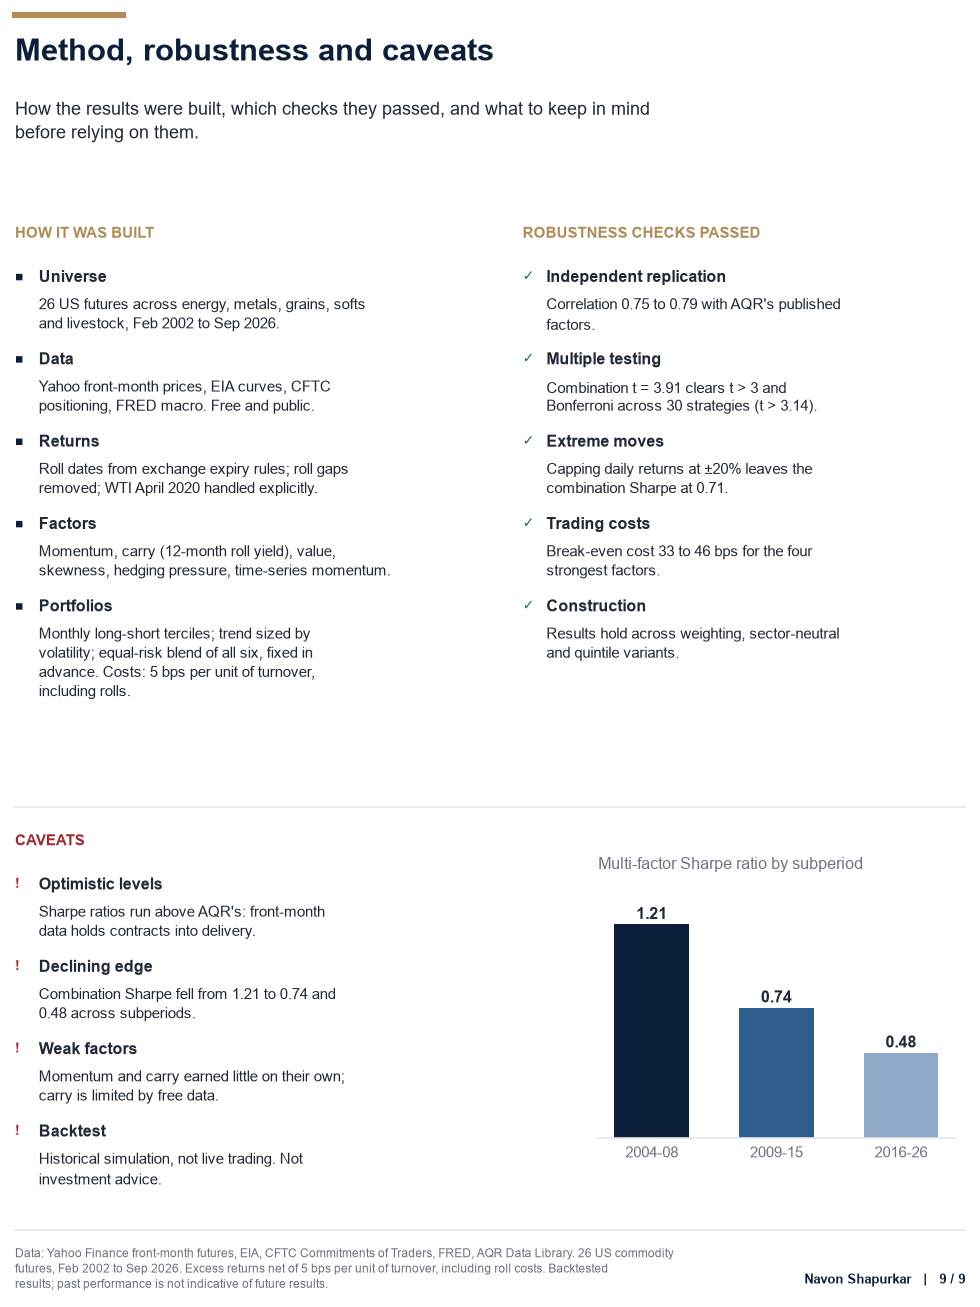

In [26]:
# ============================================================
# 06 · Cell 11b — Slide 9: subperiod chart and save
# ============================================================
ax = style_axes(fig.add_axes([0.60, 0.13, 0.33, 0.19]), STYLE, "")
bar_colours = [STYLE.navy, STYLE.color("value"), STYLE.color("mom_12_1")]
ax.bar(range(len(sharpes)), sharpes, color=bar_colours, width=0.6)
for i, value in enumerate(sharpes):
    ax.text(i, value + 0.03, f"{value:.2f}", ha="center", fontsize=7.6, color=STYLE.text, fontweight="bold")
ax.set_xticks(range(len(sharpes)))
ax.set_xticklabels(list(period_sharpe), fontsize=7.2)
ax.set_yticks([])
ax.set_ylim(0, max(sharpes) * 1.2)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.spines["bottom"].set_visible(True)
ax.spines["bottom"].set_color(STYLE.grid)
ax.tick_params(length=0)
ax.set_title("Multi-factor Sharpe ratio by subperiod", fontsize=7.6, color=STYLE.muted, loc="left")

path = slide.save(SLIDES_DIR, "09_method_caveats")
slides[9] = fig
print(f"Saved {path.name}")
fig

In [27]:
# ============================================================
# 06 · Cell 12 — Build the LinkedIn carousel PDF from the saved slides
# ============================================================
from PIL import Image

SLIDE_FILES = [
    "01_cover", "02_headline_result", "03_factor_scorecard", "04_correlations", "05_crisis_behaviour",
    "06_regimes", "07_aqr_validation", "08_long_only_tilt", "09_method_caveats",
]
missing = [name for name in SLIDE_FILES if not (SLIDES_DIR / f"{name}.png").exists()]
assert not missing, f"Missing slides: {missing}"

pages = [Image.open(SLIDES_DIR / f"{name}.png").convert("RGB") for name in SLIDE_FILES]
sizes = {page.size for page in pages}
assert sizes == {(1080, 1350)}, f"Unexpected slide sizes: {sizes}"

pdf_path = SLIDES_DIR / "commodity_factor_investing_carousel.pdf"
pages[0].save(pdf_path, save_all=True, append_images=pages[1:], resolution=150)

print(f"Carousel saved: {pdf_path}")
print(f"  pages: {len(pages)} | size: {pdf_path.stat().st_size / 1024 / 1024:.1f} MB\n")
print("Slides:")
for name in SLIDE_FILES:
    print(f"  {name}.png")

Carousel saved: C:\Users\navon\OneDrive\Desktop\Cmmodities Factor Modeling\reports\linkedin\commodity_factor_investing_carousel.pdf
  pages: 9 | size: 1.0 MB

Slides:
  01_cover.png
  02_headline_result.png
  03_factor_scorecard.png
  04_correlations.png
  05_crisis_behaviour.png
  06_regimes.png
  07_aqr_validation.png
  08_long_only_tilt.png
  09_method_caveats.png
